# War Banner (Seyan'Du)

War Banner (`SK_AURA_WAR_BANNER`) is a toggled aura. Once a second it applies a 2 s buff to the
caster and every character within 12 tiles that shares the caster's group. The buff raises armor
and weapon value by the same amount. A character can run only one aura at a time, so War Banner
and Aura of Despair are exclusive.

| | |
|---|---|
| Class | Seyan'Du (talent "War Banner") |
| Target | Caster + every visible, living character in the 25×25 square with the caster's `data[CHD_GROUP]` |
| Cost | none: no mana, endurance or upkeep |
| Cooldown | none; toggled on and off with the skill |
| Landing roll | none |
| Duration | permanent while toggled; each pulse applies or refreshes a 2 s item |
| Effect | `power = 50 + ⌊p/2⌋`; `armor[1] = weapon[1] = max(1, ⌊power/10⌋)` |
| Source | `server/src/aura/mod.rs` (`aura_power`, `apply_modifiers`, `is_valid_target`); `server/src/aura/logic.rs::pulse_aura`; `server/src/driver/skill/auras.rs::skill_war_banner_aura` |

---

# Formula

With $p$ the caster's modified skill:

$$
\text{power} = 50 + \lfloor p/2 \rfloor
\qquad
b = \max\!\left(1,\ \left\lfloor \frac{\text{power}}{10} \right\rfloor\right)
$$

Each point of armor removes 0.25 HP from every melee hit the ally takes (0.75 from type 1/2 spell
hits) as long as the hit still gets through. Each point of weapon value adds 0.25 HP to every melee
hit the ally lands. Both totals are clamped to 0..250.

| Quantity | Breakpoint |
|---|---|
| At skill 0 | +5 armor and weapon (power 50) |
| At the raise caps | +10 at 105, +11 at 120 |
| Ceiling | none: +1 per 20 skill points |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
BASE_POWER = 50

# Model

In [2]:
def banner_bonus(p):
    power = np.maximum(1, BASE_POWER + mm.idiv(p, 2))
    return np.maximum(1, mm.idiv(power, 10))


def outgoing_gain(p, wv, strength=80, target_armor=20):
    """× damage per landed melee hit an ally deals with the banner."""
    base = mm.melee_hit_hp(wv, strength, target_armor)
    after = np.array([mm.melee_hit_hp(wv + int(b), strength, target_armor) for b in np.atleast_1d(banner_bonus(p))])
    return after / base if base > 0 else np.full(after.shape, np.nan)


def incoming_cut(p, ally_armor, enemy_wv=60, strength=80):
    """Fraction of the damage per landed enemy hit that the banner removes."""
    base = mm.melee_hit_hp(enemy_wv, strength, ally_armor)
    after = mm.melee_hit_hp(enemy_wv, strength, ally_armor + banner_bonus(np.atleast_1d(p)))
    return 1 - after / base


def party_hp_per_s(p, n, swings_per_s=1.0, hits_taken_per_s=1.0, wv=40, armor=20, enemy_wv=60):
    """Extra HP dealt + HP prevented per second across `n` allies (caster included)."""
    b = banner_bonus(np.atleast_1d(p))
    dealt = np.array([mm.melee_hit_hp(wv + int(x), 80, 20) for x in b]) - mm.melee_hit_hp(wv, 80, 20)
    saved = mm.melee_hit_hp(enemy_wv, 80, armor) - mm.melee_hit_hp(enemy_wv, 80, armor + b)
    return n * (swings_per_s * dealt + hits_taken_per_s * saved)

# Validation

- `war_banner_aura_power_scales_with_skill_total`: `armor[1]` at total 100 exceeds the value at
  total 1.
- `war_banner_applies_buff_to_caster`: the caster gets and refreshes the buff with no allies
  nearby.
- `war_banner_aura_toggles_on_and_off`, `switching_auras_replaces_the_active_one`.

In [3]:
assert banner_bonus(1) == 5 and banner_bonus(100) == 10 and banner_bonus(100) > banner_bonus(1)
assert banner_bonus(0) == 5 and banner_bonus(105) == 10 and banner_bonus(120) == 11
assert banner_bonus(119) == 10 and banner_bonus(200) == 15
print("War Banner model OK")

War Banner model OK


# Plots

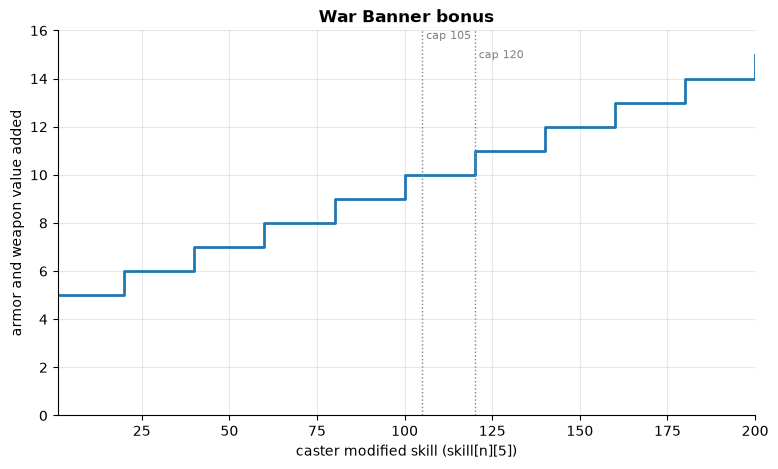

In [4]:
fig, ax = plt.subplots()
ax.step(P, banner_bonus(P), where="post")
mm.skill_axis(ax, "armor and weapon value added", "War Banner bonus")
ax.set_ylim(0, 16)
mm.mark_caps(ax)

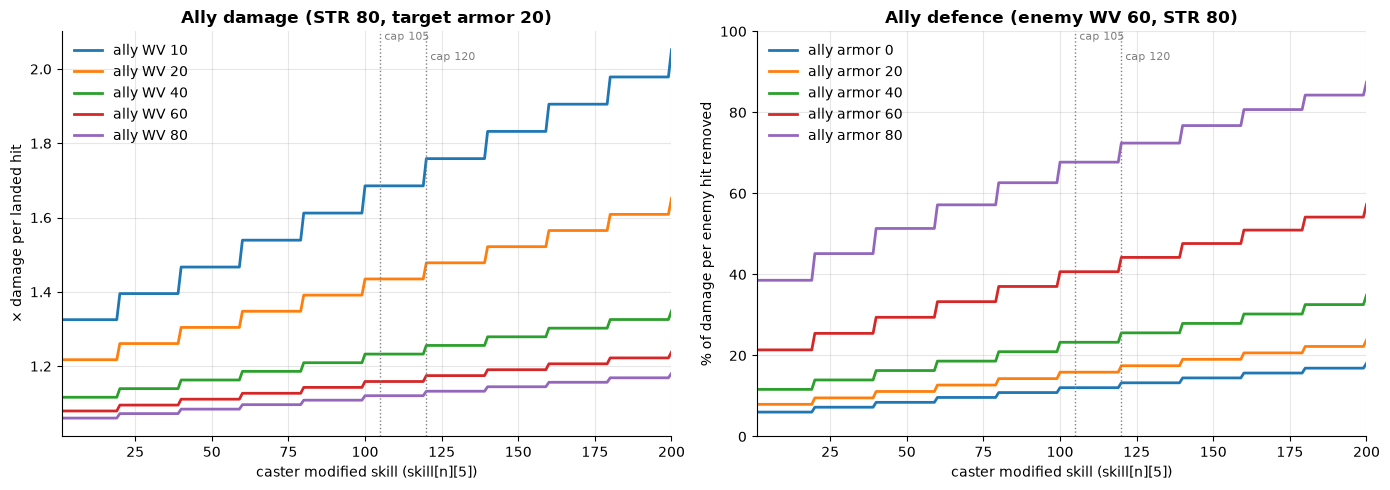

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for wv in mm.WV_SWEEP:
    ax.plot(P, outgoing_gain(P, wv), label=f"ally WV {wv}")
mm.skill_axis(ax, "× damage per landed hit", "Ally damage (STR 80, target armor 20)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for armor in mm.ARMOR_SWEEP:
    ax.plot(P, 100 * incoming_cut(P, armor), label=f"ally armor {armor}")
mm.skill_axis(ax, "% of damage per enemy hit removed", "Ally defence (enemy WV 60, STR 80)")
ax.set_ylim(0, 100)
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

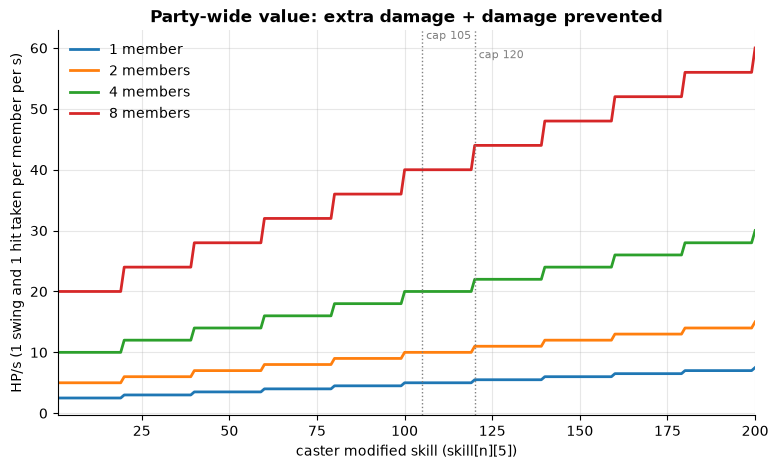

In [6]:
fig, ax = plt.subplots()
for n in (1, 2, 4, 8):
    ax.plot(P, party_hp_per_s(P, n), label=f"{n} member{'s' if n > 1 else ''}")
mm.skill_axis(ax, "HP/s (1 swing and 1 hit taken per member per s)", "Party-wide value: extra damage + damage prevented")
mm.mark_caps(ax)
ax.legend()

# Observations

- **A free, permanent party buff.** There is no cost, upkeep or roll. At skill 105 the caster and
  every same-group character within 12 tiles get +10 armor and +10 weapon value. That is +2.5 HP on
  every landed melee hit and −2.5 HP on every melee hit taken (−7.5 HP on spell hits).
- **The value is flat, so weak characters gain the most.** Against armor 20, an ally with WV 20
  deals ×1.43 per hit, WV 40 ×1.23 and WV 80 ×1.12. Against an enemy with WV 60 and STR 80, an
  ally with armor 0 takes 12% less per hit, armor 40 takes 23% less and armor 60 takes 41% less.
  High-armor allies gain the most on defence, because the bonus is a larger share of a small
  post-armor remainder.
- **It scales with party size.** With one swing landed and one hit taken per member per second,
  the banner is worth about 5 HP/s per member at skill 105, so 40 HP/s for a party of eight. A
  single caster gets 5 HP/s for free.
- **It grows slowly and does not saturate.** +1 per 20 skill points from a base of +5 at skill 0.
  Half the value at the raise cap is already there at skill 0.
- **Group targeting.** Like Aura of Despair, `is_valid_target` compares `data[CHD_GROUP]`, with no
  line-of-sight check. Ghost companions use group `65536 + owner`, so **the caster's own ghosts are
  not buffed**. Who else shares a player's group depends on the character template; I did not
  check whether that includes every player in range.
- **It competes with Aura of Despair.** Only one aura can run at a time, and both talents share
  the same prerequisites. Despair is far stronger at the same skill (−34 to every enemy attribute
  against +10 armor and weapon), so War Banner only makes sense in a large party.
- **Balance suggestions.** The numbers are modest. Treat the caster's companions as allies (group
  `65536 + caster`), and consider a smaller base with a steeper slope, for example `p/8` (+13 at
  105), so the skill matters more than the talent alone.